AOI properties to compare:

- [x] Land cover breakdown (to see potential for confusion between mangroves & dense vegetation)
- [x] Slope class distribution (to see potential for confusion from topographic shadow effects)
- [x] Mangrove cover fragmentation (to see effect of edge effects on accuracy)
- [ ] Climate type (Taylor chart showing Type 1, 2, 3? determines which months to best get imagery)

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
import rioxarray as rxr
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter

import xarray as xr
import xrspatial as xrs
from xrspatial.convolution import convolve_2d
from shapely.geometry import Polygon, MultiPolygon
from shapely import make_valid
from shapely.ops import transform
from pyproj import Transformer

# from odc.stac import stac_load, configure_s3_access
import stackstac as stk
import pystac_client
import planetary_computer as pc
from dask.distributed import Client
from pystac.extensions.projection import ProjectionExtension as proj

from dotenv import load_dotenv
from pathlib import Path

In [2]:
import warnings

warnings.filterwarnings("ignore", category=DeprecationWarning)

In [3]:
def resolve_metadata(item, asset_key, env_opts=None, rescale=False):
    """
    Extract metadata from STAC or raster attributes.
    Includes: dtype, nodata, resolution, scale, and offset.
    CRS/EPSG is treated separately.
    """
    asset = item.assets[asset_key]
    band = (asset.extra_fields.get('raster:bands') or [{}])[0]

    with rio.Env(**(env_opts or {})), rio.open(asset.href) as src:
        dt_name = band.get("data_type") or src.dtypes[0]
        nodata = band.get("nodata", src.nodata)
        scale = band.get("scale",  src.scales[0])
        offset = band.get("offset", src.offsets[0])
        epsg, resolution = src.crs.to_epsg(), src.res[0]

    # # Try extracting STAC metadtata
    # dt_name = band.get("data_type", band.get("dtype"))
    # nodata = band.get("nodata")
    # resolution = band.get("spatial_resolution")
    # scale, offset = band.get("scale", 1), band.get("offset", 0)

    # rds = rxr.open_rasterio(asset.href, chunks=True)

    # # Extract metadata from raster itself if absent from STAC
    # if dt_name is None:
    #     dt_name = rds.dtype
    # if nodata is None:
    #     nodata = rds.rio.nodata
    # if resolution is None:
    #     resolution = rds.rio.resolution()[0]
    # if scale is None:
    #     scale = rds.scale_factor
    # if offset is None:
    #     offset = rds.add_offset

    dtype = np.dtype(dt_name)

    if rescale and (scale != 1 or offset != 0):
        dtype = np.dtype(np.float32)
    
    return dtype, dtype.type(nodata), scale, offset, epsg, resolution

In [4]:
def search_catalog_in_aoi(geom, catalog, collection_id, year=2021):
    """
    Search for items from a given collection that intersect a specified geometry.
    Different collections have different year ranges.
    """
    search = catalog.search(
        collections=[collection_id],
        intersects=geom,
        datetime=f'{year}-01-01/{year}-12-31'
    )

    items = search.item_collection()

    if len(items) == 0:
        raise ValueError(f'Search in catalog {collection_id} returned no results')

    # epsg = proj.ext(items[0]).epsg
    # nodata = items[0].assets["data"].extra_fields["raster:bands"][0]["nodata"]

    return items

In [5]:
def load_clipped(geom, catalog, collection_id, asset_key, env_opts=None, **kw):
    """Load STAC items into a DataArray, rescale if needed, and clip using a specified geometry."""
    items = search_catalog_in_aoi(geom, catalog, collection_id, **kw)
    
    # epsg = proj.ext(items[0]).epsg

    # If no specified fill value, use nodata value
    dtype, fill, scale, offset, epsg, resolution = resolve_metadata(items[0], asset_key, env_opts)

    gdal_env = stk.DEFAULT_GDAL_ENV.updated(always=env_opts) if env_opts else stk.DEFAULT_GDAL_ENV

    # with rio.Env(env_opts):
    da = stk.stack(
        items,
        epsg=epsg,
        assets=[asset_key],
        resolution=resolution,
        bounds_latlon=geom.bounds,
        dtype=dtype,
        fill_value=fill,
        rescale=False,
        gdal_env=gdal_env
    )

    # Flatten DataArray if "time" is one of the dimensions
    if "time" in list(da.dims):
        da = stk.mosaic(
            da,
            dim="time",
            axis=None,
            nodata=fill
        ).squeeze("band", drop=True)

    # Rescale and add offset, if available
    if scale != 1 or offset != 0:
        da = (da.astype(np.float32).where(da != fill) * scale) + offset

    # Clip loaded DataArray to geometry to limit memory usage
    transformer = Transformer.from_crs('EPSG:4326', epsg, always_xy=True)
    geom = transform(transformer.transform, geom)
    da = da.rio.clip([geom], epsg, drop=True)

    return da

In [6]:
def categorical_counts(da, categories):
    """Get pixel counts per unique value in a categorical raster."""
    counts = np.bincount(da.compute().values.ravel(), minlength=max(categories) + 1)
    return pd.Series(counts[list(categories)], index=categories)

In [7]:
def binned_counts(da, bins):
    """Get pixel counts per class in a binned continuous raster."""
    vals = da.values.ravel()
    vals = vals[np.isfinite(vals)]
    return pd.Series(np.histogram(vals, bins=bins)[0])

In [8]:
def moving_mean(da, size=5):
    """Lazy moving-window mean over the last two dims (y, x)."""
    pad = size // 2

    def _f(block):
        return uniform_filter(block, size=size, mode="constant", cval=0.0)

    out = da.astype(np.float32).fillna(0).data.map_overlap(
        _f, depth=pad, boundary="none",
        dtype=np.float32, meta=np.array((), dtype=np.float32),
    )
    return da.copy(data=out).astype(np.float32)

In [9]:
def get_percent_share(df, categories, id_vars=['aoi']):
    """Get per-class percent share in AOI area, ready for plotting."""
    # Melt DataFrame for easier percent-share calculation
    df_melt = df.melt(
        id_vars=id_vars,
        value_vars=list(categories),
        var_name='category_id',
        value_name='px_count'
    )

    df_melt['pct_in_aoi'] = df_melt['px_count'] / df_melt.groupby(id_vars)['px_count'].transform('sum')

    # Unmelt DataFrame such that different classes are individual columns
    df_pivot = df_melt.pivot(
        index=id_vars,
        columns=['category_id'],
        values=['pct_in_aoi', 'px_count']
    ).reset_index()

    return df_pivot

In [43]:
def plot_percent_share(
        df, 
        category_names, 
        legend_title,
        colors=None,
        colormap=None, 
        var_index='aoi', 
        var_plot='pct_in_aoi',
    ):
    """Plots the percent share of each class per AOI."""
    fig, ax = plt.subplots(layout='constrained', figsize=(14,7))

    if colors is None and colormap is None:
        raise ValueError("One of colors or colormap should be specified.")
    elif colors is not None and colormap is not None:
        raise ValueError("Only one of colors or colormap should be specified.")

    df.set_index(var_index).plot(
        kind='barh',
        stacked=True,
        # x='aoi',
        y=var_plot,
        # column='lulc',
        color=colors,
        colormap=colormap,
        ax=ax,
        legend=False
    )

    fig.legend(category_names, title=legend_title, loc='outside right upper')

    return ax

Prepare input directories 

In [11]:
DIR_IMAGES = Path("C:\\Users\\remot\\Documents\\Jerome\\03_Independent_Research\\20260630 Mangrove and Seagrass Monitoring\\03_Data_management\\01_Raw_data\\Rasters")
fps_images = list(DIR_IMAGES.glob("*_PlanetScope8band_*"))

# Only use a specific date for Hinatuan
fps_images = [fp for fp in fps_images if "Hinatuan" not in fp.stem or "20210729" in fp.stem]

for fp in fps_images:
    print(fp)

C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\01_Raw_data\Rasters\Busuanga-Palawan_PlanetScope8band_20240421.zip
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\01_Raw_data\Rasters\Calauag-Quezon_PlanetScope8band_20250804
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\01_Raw_data\Rasters\DumaranIsland-Palawan_PlanetScope8band_20220524
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\01_Raw_data\Rasters\Hinatuan-SurigaoDelSur_PlanetScope8band_20210729
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\01_Raw_data\Rasters\Infanta-Quezon_PlanetScope8band_20210903
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Mo

In [12]:
DIR_AOIs = Path().resolve().parent / 'output'
fps_aoi = list(DIR_AOIs.glob("*_AOI_MangroveSeagrassMapping*"))

aoi_names = [fp.stem.split("-")[0] for fp in fps_images]
fps_aoi = [fp for fp in fps_aoi if fp.stem.split("_")[0] in aoi_names]

for fp in fps_aoi:
    print(fp)

C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\output\Busuanga_AOI_MangroveSeagrassMapping.geojson
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\output\Calauag_AOI_MangroveSeagrassMapping.geojson
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\output\DumaranIsland_AOI_MangroveSeagrassMapping.geojson
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\output\Hinatuan_AOI_MangroveSeagrassMapping.geojson
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\output\Infanta_AOI_MangroveSeagrassMapping.geojson
C:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring

0. Prepare PySTAC client, STAC catalog, and AOIs GeoDataFrame

In [13]:
client = Client(processes=False)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://192.168.30.117:8787/status,
Dashboard: http://192.168.30.117:8787/status,Workers: 1
Total threads: 20,Total memory: 15.63 GiB
Status: running,Using processes: False
Comm: inproc://192.168.30.117/4028/1,Workers: 0
Dashboard: http://192.168.30.117:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: inproc://192.168.30.117/4028/4,Total threads: 20
Dashboard: http://192.168.30.117:49789/status,Memory: 15.63 GiB
Nanny: None,


c:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\.venv\Lib\site-packages\dask\array\chunk.py:288: RuntimeWarning: invalid value encountered in cast
  return x.astype(astype_dtype, **kwargs)
c:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\.venv\Lib\site-packages\dask\array\chunk.py:288: RuntimeWarning: invalid value encountered in cast
  return x.astype(astype_dtype, **kwargs)
c:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\.venv\Lib\site-packages\dask\array\chunk.py:288: RuntimeWarning: invalid value encountered in cast
  return x.astype(astype_dtype, **kwargs)
c:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\.venv\Lib\site-packages\dask\array\chunk.py:288: RuntimeWarning: 

In [14]:
url_pc = 'https://planetarycomputer.microsoft.com/api/stac/v1/'
catalog_pc = pystac_client.Client.open(url_pc, modifier=pc.sign_inplace)

In [15]:
# Compile all AOIs in one DataFrame
df_aoi = pd.concat([gpd.read_file(fp) for fp in fps_aoi], ignore_index=True)
df_aoi['aoi'] = [fp.stem.split("_")[0] for fp in fps_aoi]
df_aoi['aoi'] = df_aoi['aoi'].str.replace('^([A-Z].*)([A-Z].*)$', '\\1 \\2', regex=True)
df_aoi = df_aoi[~df_aoi['aoi'].str.contains('Dumaran|Calauag')]

# Convert to GeoDataFrame
gdf_aoi = gpd.GeoDataFrame(data=df_aoi, geometry=df_aoi['geometry']).drop(columns=['layer', 'path']).to_crs('EPSG:4326')
gdf_aoi = gdf_aoi[['aoi', 'geometry']]

# Convert GeometryCollection to MultiPolygon
is_geomcoll = gdf_aoi.geom_type == 'GeometryCollection'
if len(gdf_aoi[is_geomcoll]) > 0:
    polygons = [p for p in gdf_aoi[is_geomcoll].geometry.values[0].geoms if isinstance(p, Polygon)]
    new_multipoly = MultiPolygon([p for p in polygons])
    gdf_aoi.geometry = gdf_aoi[~is_geomcoll].geometry.to_list() + [new_multipoly]
gdf_aoi = gdf_aoi.reset_index(drop=True)

gdf_aoi

,aoi,geometry
0,Busuanga,"MULTIPOLYGON (((119.83166 11.98065, 119.83201 ..."
1,Hinatuan,"MULTIPOLYGON (((126.26826 8.31473, 126.26896 8..."
2,Infanta,"MULTIPOLYGON (((121.61302 14.56564, 121.61201 ..."
3,Roxas City,"MULTIPOLYGON (((122.67848 11.56349, 122.67709 ..."
4,Zamboanga City,"MULTIPOLYGON (((122.0571 6.87274, 122.06434 6...."


1) Land cover breakdown (using ESRI 10-meter land cover)

In [16]:
LAND_COVER_CATEGORIES = {
    1: "Water",
    2: "Trees",
    4: "Flooded Vegetation",
    5: "Crops",
    7: "Built Area",
    8: "Bare Ground",
    9: "Snow/Ice",
    10: "Clouds",
    11: "Rangeland"
}

In [17]:
LAND_COVER_COLORS = {
    1: '#419bdf',
    2: '#397d49',
    4: '#7a87c6',
    5: '#e49635',
    7: '#c4281b',
    8: '#a59b8f',
    9: '#a8ebff',
    10: '#616161',
    11: '#e3e2c3'
}

In [18]:
lulc_coll_id = 'io-lulc-annual-v02'
lulc_asset_key = 'data'
lulc_year = 2021

results = {}

for _, row in gdf_aoi.iterrows():
    geom = make_valid(row['geometry'], method='structure')
    
    print(f'Processing {row['aoi']}', end='... ')

    # results[row['aoi']] = lulc_histogram(geom, catalog, collection_id)
    results[row['aoi']] = categorical_counts(
        load_clipped(
            geom=geom, 
            catalog=catalog_pc,
            collection_id=lulc_coll_id,
            asset_key=lulc_asset_key,
            year=lulc_year 
        ),
        list(LAND_COVER_CATEGORIES.keys())
    )

    print('Done!')

df_lulc = pd.DataFrame(results).T.reset_index(names=['aoi'])
df_lulc

Processing Busuanga... 

c:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\.venv\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 15.56 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Done!
Processing Hinatuan... Done!
Processing Infanta... Done!
Processing Roxas City... Done!
Processing Zamboanga City... 

c:\Users\remot\Documents\Jerome\03_Independent_Research\20260630 Mangrove and Seagrass Monitoring\03_Data_management\03_Scripts\.venv\Lib\site-packages\distributed\client.py:3429: UserWarning: Sending large graph of size 38.38 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


Done!


,aoi,1,2,4,5,7,8,9,10,11
0,Busuanga,392426,812361,10213,6970,44291,283,2,4,248062
1,Hinatuan,228684,620529,132179,32999,21054,107,0,28,28124
2,Infanta,184085,456948,192021,217669,102645,26,0,34,7287
3,Roxas City,1657677,116747,87854,642568,332542,202,0,86,15237
4,Zamboanga City,184646,665615,437032,129233,319965,945,0,1325,210619


In [19]:
df_lulc_plot = get_percent_share(df_lulc, LAND_COVER_CATEGORIES.keys())
df_lulc_plot

aoi pct_in_aoi                                \
category_id                          1         2         4         5   
0                  Busuanga   0.259093  0.536349  0.006743  0.004602   
1                  Hinatuan   0.214988  0.583366  0.124263  0.031023   
2                   Infanta   0.158596  0.393678  0.165433  0.187530   
3                Roxas City   0.581047  0.040922  0.030794  0.225232   
4            Zamboanga City   0.094720  0.341450  0.224190  0.066294   

                                                                px_count  \
category_id         7         8         9        10        11          1   
0            0.029242  0.000187  0.000001  0.000003  0.163779   392426.0   
1            0.019793  0.000101  0.000000  0.000026  0.026440   228684.0   
2            0.088433  0.000022  0.000000  0.000029  0.006278   184085.0   
3            0.116562  0.000071  0.000000  0.000030  0.005341  1657677.0   
4            0.164137  0.000485  0.000000  0.000680  0.108044   184646.0   

                                                                         \
category_id         2         4         5         7      8    9      10   
0            812361.0   10213.0    6970.0   44291.0  283.0  2.0     4.0   
1            620529.0  132179.0   32999.0   21054.0  107.0  0.0    28.0   
2            456948.0  192021.0  217669.0  102645.0   26.0  0.0    34.0   
3            116747.0   87854.0  642568.0  332542.0  202.0  0.0    86.0   
4            665615.0  437032.0  129233.0  319965.0  945.0  0.0  1325.0   

                       
category_id        11  
0            248062.0  
1             28124.0  
2              7287.0  
3             15237.0  
4            210619.0

<Axes: ylabel='aoi'>

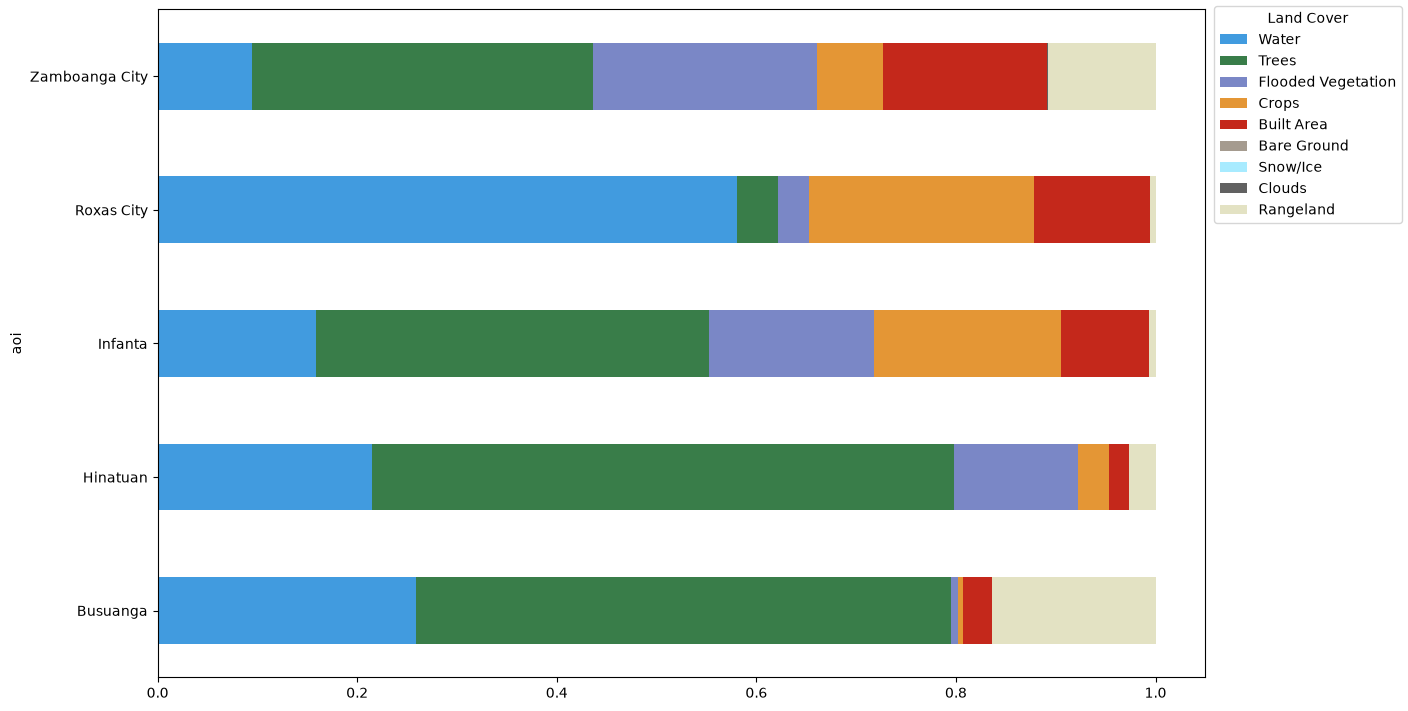

In [20]:
plot_percent_share(df_lulc_plot, LAND_COVER_CATEGORIES.values(), 'Land Cover', colors=LAND_COVER_COLORS)

2. Slope class breakdown (using NASADEM)

In [21]:
SLOPE_CATEGORIES = {
    0: 'Level to nearly level',
    1: 'Gently sloping to undulating',
    2: 'Undulating to rolling',
    3: 'Rolling to moderately steep',
    4: 'Steep',
    5: 'Very steep'
}

In [22]:
SLOPE_BINS = [0, 3, 8, 18, 30, 50, np.inf]

In [23]:
dem_coll_id = 'nasadem'
dem_asset_key = 'elevation'
dem_year = 2000

results = {}

for _, row in gdf_aoi.iterrows():
    geom = make_valid(row['geometry'], method='structure')
    
    print(f'Processing {row['aoi']}', end='... ')

    da_elev = load_clipped(
        geom=geom,
        catalog=catalog_pc,
        collection_id=dem_coll_id,
        asset_key=dem_asset_key,
        year=dem_year
    )

    # Compute slope in degrees using xarray-spatial
    da_slope_deg = xrs.slope(da_elev.rio.reproject("EPSG:32651"))

    # Convert degrees to percent slope
    da_slope_rad = np.deg2rad(da_slope_deg)
    da_slope_pct = np.tan(da_slope_rad) * 100.0

    results[row['aoi']] = binned_counts(da_slope_pct, SLOPE_BINS)

    print('Done!')

df_slope = pd.DataFrame(results).T.reset_index(names=['aoi'])
df_slope

Processing Busuanga... Done!
Processing Hinatuan... Done!
Processing Infanta... Done!
Processing Roxas City... Done!
Processing Zamboanga City... Done!


,aoi,0,1,2,3,4,5
0,Busuanga,1588729,33972,34920,25490,24855,19443
1,Hinatuan,456356,43394,27141,8377,3583,8379
2,Infanta,540668,42685,9599,8147,9080,11026
3,Roxas City,676779,124778,30114,4466,2197,909
4,Zamboanga City,4100862,72234,43483,17133,8278,17730


In [24]:
df_slope_plot = get_percent_share(df_slope, SLOPE_CATEGORIES)
df_slope_plot

aoi pct_in_aoi                                \
category_id                          0         1         2         3   
0                  Busuanga   0.919718  0.019666  0.020215  0.014756   
1                  Hinatuan   0.833938  0.079298  0.049597  0.015308   
2                   Infanta   0.870354  0.068713  0.015452  0.013115   
3                Roxas City   0.806416  0.148679  0.035882  0.005321   
4            Zamboanga City   0.962707  0.016957  0.010208  0.004022   

                                  px_count                              \
category_id         4         5          0         1        2        3   
0            0.014389  0.011256  1588729.0   33972.0  34920.0  25490.0   
1            0.006548  0.015312   456356.0   43394.0  27141.0   8377.0   
2            0.014617  0.017749   540668.0   42685.0   9599.0   8147.0   
3            0.002618  0.001083   676779.0  124778.0  30114.0   4466.0   
4            0.001943  0.004162  4100862.0   72234.0  43483.0  17133.0   

                               
category_id        4        5  
0            24855.0  19443.0  
1             3583.0   8379.0  
2             9080.0  11026.0  
3             2197.0    909.0  
4             8278.0  17730.0

C:\Users\remot\AppData\Local\Temp\ipykernel_4028\977473675.py:18: UserWarning: 'color' and 'colormap' cannot be used simultaneously. Using 'color'
  df.set_index(var_index).plot(


<Axes: ylabel='aoi'>

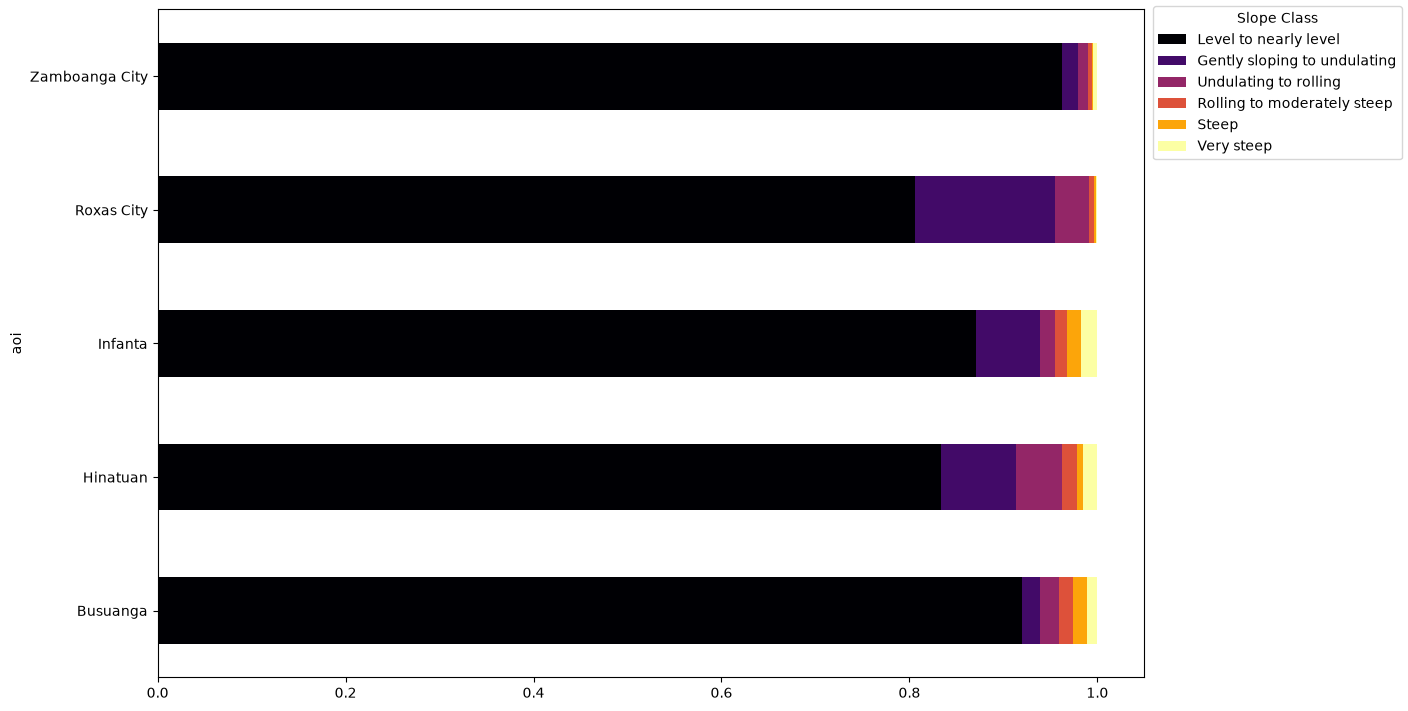

In [48]:
plot_percent_share(df_slope_plot, SLOPE_CATEGORIES.values(), 'Slope Class', colormap='inferno')

3. Mangrove cover density breakdown

Foest cover density within a certain radius, as proposed in [FAO Open Knowledge "Measuring forest configuration and spatial integrity"](https://openknowledge.fao.org/server/api/core/bitstreams/a1dcdadf-6199-4e00-bf8b-1e31de9c4a05/content/ad654e04.htm)

In [26]:
load_dotenv()

True

In [ ]:
url_maap = "https://stac.maap-project.org/"
catalog_maap = pystac_client.Client.open(url_maap)

# Learned that no-sign request works because GMW is hosted on NASA MAAP, not ESA
# Typically, downloading datasets from ESA MAAP requires auth key
MAAP_ENV = dict(AWS_NO_SIGN_REQUEST="YES")

In [33]:
FOREST_COVER_CATEGORIES = {
    0: '0-20%',
    1: '21-40%',
    2: '41-60%',
    3: '61-80%',
    4: '81-100%'
}

In [31]:
FOREST_COVER_BINS = [0, 20, 40, 60, 80, 100]

In [39]:
gmw_coll_id = 'global-mangrove-watch-3.0'
gmw_asset_key = 'cog'
gmw_year = 2020

# Define shared kernel for later focal statistics (via convolve2d)
kernel = np.array([
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
    [1, 1, 1, 1, 1],
])

kernel_sum = kernel.astype(np.float32).sum()

results = {}

for _, row in gdf_aoi.iterrows():
    geom = make_valid(row['geometry'], method='structure')
    
    print(f'Processing {row['aoi']}', end='... ')

    da_gmw = load_clipped(
        geom=geom,
        catalog=catalog_maap,
        collection_id=gmw_coll_id,
        asset_key=gmw_asset_key,
        year=gmw_year,
        env_opts=MAAP_ENV
    ).rio.reproject("EPSG:32651")

    print(f'DataArray for {row['aoi']} loaded', end='... ')

    # Neighborhood forest cover density via xrspatial.convolution.convolve2d
    cover_pct_vals = convolve_2d(
        da_gmw.data, 
        kernel, 
        boundary='nearest'
    )

    da_cover_pct = xr.DataArray(
        cover_pct_vals / kernel_sum * 100,
        coords=da_gmw.coords,
        dims=da_gmw.dims,
        attrs=da_gmw.attrs
    ).where(da_gmw == 1)

    print(f'Moving mean computed...', end='... ')

    results[row['aoi']] = binned_counts(da_cover_pct, FOREST_COVER_BINS)

    print('Done!')

df_cover = pd.DataFrame(results).T.reset_index(names=['aoi'])
df_cover

Processing Busuanga... DataArray for Busuanga loaded... Moving mean computed...... Done!
Processing Hinatuan... DataArray for Hinatuan loaded... Moving mean computed...... Done!
Processing Infanta... DataArray for Infanta loaded... Moving mean computed...... Done!
Processing Roxas City... DataArray for Roxas City loaded... Moving mean computed...... Done!
Processing Zamboanga City... DataArray for Zamboanga City loaded... Moving mean computed...... Done!


,aoi,0,1,2,3,4
0,Busuanga,88,742,2397,3650,9727
1,Hinatuan,159,1656,4808,8509,23638
2,Infanta,180,1212,4242,7884,36031
3,Roxas City,1335,5516,8361,10084,15715
4,Zamboanga City,731,2951,6911,9957,34686


In [40]:
df_gmw_plot = get_percent_share(df_cover, FOREST_COVER_CATEGORIES.keys())
df_gmw_plot

aoi pct_in_aoi                                \
category_id                          0         1         2         3   
0                  Busuanga   0.005300  0.044688  0.144363  0.219827   
1                  Hinatuan   0.004101  0.042713  0.124013  0.219474   
2                   Infanta   0.003633  0.024461  0.085612  0.159115   
3                Roxas City   0.032552  0.134500  0.203872  0.245885   
4            Zamboanga City   0.013234  0.053425  0.125118  0.180263   

                      px_count                                    
category_id         4        0       1       2        3        4  
0            0.585823     88.0   742.0  2397.0   3650.0   9727.0  
1            0.609698    159.0  1656.0  4808.0   8509.0  23638.0  
2            0.727179    180.0  1212.0  4242.0   7884.0  36031.0  
3            0.383190   1335.0  5516.0  8361.0  10084.0  15715.0  
4            0.627960    731.0  2951.0  6911.0   9957.0  34686.0

C:\Users\remot\AppData\Local\Temp\ipykernel_4028\977473675.py:18: UserWarning: 'color' and 'colormap' cannot be used simultaneously. Using 'color'
  df.set_index(var_index).plot(


<Axes: ylabel='aoi'>

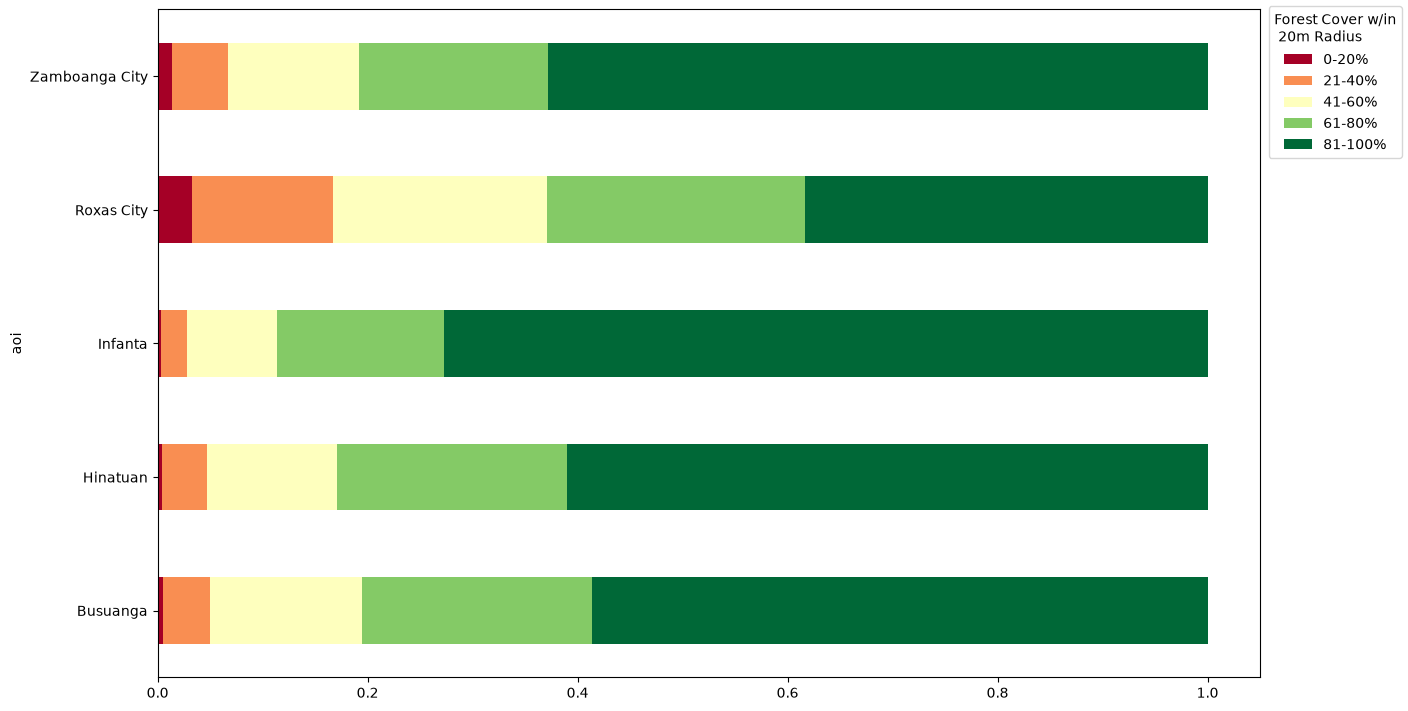

In [47]:
plot_percent_share(df_gmw_plot, FOREST_COVER_CATEGORIES.values(), legend_title='Forest Cover w/in\n 20m Radius', colormap='RdYlGn')